In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

# Lab: Searching for the Optimal Price

We use grid search to select a price between $0 and $70. 

In [2]:
lab_rng = np.random.default_rng(100)

price = 10.00
experiment_size = 200

customer_revenue = sales(
    price,
    mean_customers=experiment_size,
    rng=lab_rng
) * price

n_customers = len(customer_revenue)
total_revenue = customer_revenue.sum()
mean_revenue = customer_revenue.mean()

print(f"Price: ${price:.2f}")
print(f"Number of customers: {n_customers}")
print(f"Total revenue: ${total_revenue:.2f}")
print(f"Mean revenue per customer: ${mean_revenue:.3f}")

Price: $10.00
Number of customers: 216
Total revenue: $2150.00
Mean revenue per customer: $9.954


In [3]:
# Store customer-level revenue for each tested price
revenue_by_price = {}
revenue_by_price[price] = customer_revenue.copy()

# Store a summary of each experiment
experiment_records = []

experiment_records.append({
    "round": 1,
    "price": price,
    "n_customers": n_customers,
    "total_revenue": total_revenue,
    "mean_revenue": mean_revenue
})

results = pd.DataFrame(experiment_records)
results

,round,price,n_customers,total_revenue,mean_revenue
0,1,10.0,216,2150.0,9.953704


In [4]:
# Coarse grid: prices from $5 to $70, in $5 increments
initial_prices = np.arange(5, 71, 5)

for price in initial_prices:

    # Keep the experiment already completed at $10
    if price in revenue_by_price:
        continue

    # Same experiment size as our first experiment
    customer_revenue = sales(
        price,
        mean_customers=experiment_size,
        rng=lab_rng
    ) * price

    n_customers = len(customer_revenue)
    total_revenue = customer_revenue.sum()
    mean_revenue = customer_revenue.mean()

    # Save customer-level data
    revenue_by_price[price] = customer_revenue.copy()

    # Save this experiment's summary
    experiment_records.append({
        "round": 1,
        "price": price,
        "n_customers": n_customers,
        "total_revenue": total_revenue,
        "mean_revenue": mean_revenue
    })

results = pd.DataFrame(experiment_records)
results.sort_values("price")

,round,price,n_customers,total_revenue,mean_revenue
1,1,5.0,176,880.0,5.000000
0,1,10.0,216,2150.0,9.953704
2,1,15.0,216,1875.0,8.680556
3,1,20.0,192,1800.0,9.375000
4,1,25.0,210,2375.0,11.309524
5,1,30.0,205,2520.0,12.292683
6,1,35.0,195,665.0,3.410256
7,1,40.0,191,1280.0,6.701571
8,1,45.0,175,945.0,5.400000
9,1,50.0,199,1550.0,7.788945


In [5]:
# Summarize all customer data collected at each price
price_summary = []

for price in sorted(revenue_by_price):

    customer_revenue = revenue_by_price[price]

    n_customers = len(customer_revenue)
    mean_revenue = customer_revenue.mean()

    # Same standard error calculation used in the teacher's notebook
    standard_error = np.sqrt(
        np.var(customer_revenue, ddof=1) / n_customers
    )

    # Approximate 90% confidence interval
    ci_lower = mean_revenue - 1.645 * standard_error
    ci_upper = mean_revenue + 1.645 * standard_error

    price_summary.append({
        "price": price,
        "n_customers": n_customers,
        "mean_revenue": mean_revenue,
        "standard_error": standard_error,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    })

price_summary = pd.DataFrame(price_summary)
price_summary.round(3)

,price,n_customers,mean_revenue,standard_error,ci_lower,ci_upper
0,5.0,176,5.000,0.000,5.000,5.000
1,10.0,216,9.954,0.046,9.878,10.030
2,15.0,216,8.681,0.505,7.850,9.511
3,20.0,192,9.375,0.722,8.187,10.563
4,25.0,210,11.310,0.861,9.894,12.725
5,30.0,205,12.293,1.033,10.593,13.992
6,35.0,195,3.410,0.745,2.184,4.636
7,40.0,191,6.702,1.084,4.919,8.484
8,45.0,175,5.400,1.109,3.576,7.224
9,50.0,199,7.789,1.289,5.669,9.909


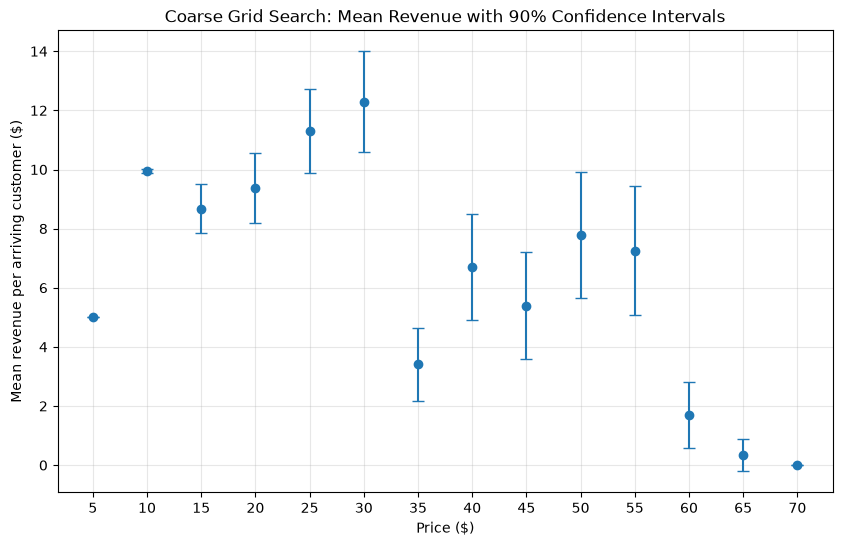

In [6]:
plt.figure(figsize=(10, 6))

plt.errorbar(
    price_summary["price"],
    price_summary["mean_revenue"],
    yerr=1.645 * price_summary["standard_error"],
    fmt="o",
    capsize=4
)

plt.xlabel("Price ($)")
plt.ylabel("Mean revenue per arriving customer ($)")
plt.title("Coarse Grid Search: Mean Revenue with 90% Confidence Intervals")
plt.xticks(initial_prices)
plt.grid(alpha=0.3)

plt.show()

In [7]:
# Sort the coarse-grid results by price
grid_results = price_summary.sort_values("price").reset_index(drop=True)

candidate_regions = []

for i in range(1, len(grid_results) - 1):

    left = grid_results.iloc[i - 1]
    current = grid_results.iloc[i]
    right = grid_results.iloc[i + 1]

    if (
        current["mean_revenue"] > left["mean_revenue"]
        and current["mean_revenue"] > right["mean_revenue"]
    ):
        candidate_regions.append({
            "candidate_price": current["price"],
            "lower_price": left["price"],
            "upper_price": right["price"]
        })

candidate_regions = pd.DataFrame(candidate_regions)
candidate_regions

,candidate_price,lower_price,upper_price
0,10.0,5.0,15.0
1,30.0,25.0,35.0
2,40.0,35.0,45.0
3,50.0,45.0,55.0


In [8]:
# Select the price with the highest observed mean revenue
best_index = price_summary["mean_revenue"].idxmax()
best_price = price_summary.loc[best_index, "price"]

revenue_best = revenue_by_price[best_price]

comparisons = []

for price in candidate_regions["candidate_price"]:

    # No need to compare a price with itself
    if price == best_price:
        continue

    revenue_candidate = revenue_by_price[price]

    # Difference: candidate minus current best
    delta_R = revenue_candidate.mean() - revenue_best.mean()

    # Teacher's two-sample standard error formula
    std_error = np.sqrt(
        np.var(revenue_candidate, ddof=1) / len(revenue_candidate)
        + np.var(revenue_best, ddof=1) / len(revenue_best)
    )

    ci_lower = delta_R - 1.645 * std_error
    ci_upper = delta_R + 1.645 * std_error

    comparisons.append({
        "candidate_price": price,
        "reference_price": best_price,
        "difference": delta_R,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    })

comparisons = pd.DataFrame(comparisons)
comparisons.round(3)

,candidate_price,reference_price,difference,ci_lower,ci_upper
0,10.0,30.0,-2.339,-4.040,-0.638
1,40.0,30.0,-5.591,-8.054,-3.128
2,50.0,30.0,-4.504,-7.220,-1.787


In [9]:
# Generate two interior prices for each candidate region
refined_prices = []

for i in range(len(candidate_regions)):

    lower = candidate_regions.iloc[i]["lower_price"]
    upper = candidate_regions.iloc[i]["upper_price"]

    step = (upper - lower) / 3

    refined_prices.append(round(lower + step, 2))
    refined_prices.append(round(lower + 2 * step, 2))

# Remove duplicate prices and sort
refined_prices = sorted(set(refined_prices))

print("New prices to test:", refined_prices)

New prices to test: [np.float64(8.33), np.float64(11.67), np.float64(28.33), np.float64(31.67), np.float64(38.33), np.float64(41.67), np.float64(48.33), np.float64(51.67)]


In [10]:
for price in refined_prices:

    # Avoid repeating an experiment already recorded
    if price in revenue_by_price:
        continue

    # Default sample size for exploratory regions
    sample_size = 100

    # Allocate more customers near the current best price
    for i in range(len(candidate_regions)):

        region = candidate_regions.iloc[i]

        if (
            region["candidate_price"] == best_price
            and region["lower_price"] <= price <= region["upper_price"]
        ):
            sample_size = 200

    # Collect customer revenue, following the teacher's code
    customer_revenue = sales(
        price,
        mean_customers=sample_size,
        rng=lab_rng
    ) * price

    n_customers = len(customer_revenue)
    total_revenue = customer_revenue.sum()
    mean_revenue = customer_revenue.mean()

    # Save customer-level data
    revenue_by_price[price] = customer_revenue.copy()

    # Append this batch to the experiment record
    experiment_records.append({
        "round": 2,
        "price": price,
        "n_customers": n_customers,
        "total_revenue": total_revenue,
        "mean_revenue": mean_revenue
    })

# Display the second-round results
results = pd.DataFrame(experiment_records)
results[results["round"] == 2].sort_values("price")

,round,price,n_customers,total_revenue,mean_revenue
14,2,8.33,91,758.03,8.330000
15,2,11.67,93,1061.97,11.419032
16,2,28.33,189,2464.71,13.040794
17,2,31.67,182,1583.50,8.700549
18,2,38.33,114,804.93,7.060789
19,2,41.67,83,541.71,6.526627
20,2,48.33,82,289.98,3.536341
21,2,51.67,84,671.71,7.996548


In [11]:
price_summary = []

for price in sorted(revenue_by_price):

    customer_revenue = revenue_by_price[price]

    n_customers = len(customer_revenue)
    mean_revenue = customer_revenue.mean()

    standard_error = np.sqrt(
        np.var(customer_revenue, ddof=1) / n_customers
    )

    ci_lower = mean_revenue - 1.645 * standard_error
    ci_upper = mean_revenue + 1.645 * standard_error

    price_summary.append({
        "price": price,
        "n_customers": n_customers,
        "mean_revenue": mean_revenue,
        "standard_error": standard_error,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    })

price_summary = pd.DataFrame(price_summary)

# Show the five highest observed mean revenues
price_summary.sort_values(
    "mean_revenue", ascending=False
).head(5).round(3)

,price,n_customers,mean_revenue,standard_error,ci_lower,ci_upper
7,28.33,189,13.041,1.030,11.347,14.735
8,30.00,205,12.293,1.033,10.593,13.992
3,11.67,93,11.419,0.176,11.129,11.709
6,25.00,210,11.310,0.861,9.894,12.725
2,10.00,216,9.954,0.046,9.878,10.030


In [12]:
# Find the current best price automatically
best_index = price_summary["mean_revenue"].idxmax()
best_price = price_summary.loc[best_index, "price"]

revenue_best = revenue_by_price[best_price]

comparisons = []
prices_to_retest = [best_price]

for price in sorted(revenue_by_price):

    if price == best_price:
        continue

    revenue_candidate = revenue_by_price[price]

    delta_R = revenue_candidate.mean() - revenue_best.mean()

    std_error = np.sqrt(
        np.var(revenue_candidate, ddof=1) / len(revenue_candidate)
        + np.var(revenue_best, ddof=1) / len(revenue_best)
    )

    ci_lower = delta_R - 1.645 * std_error
    ci_upper = delta_R + 1.645 * std_error

    # Keep prices not clearly worse in this comparison
    keep = ci_upper >= 0

    if keep:
        prices_to_retest.append(price)

    comparisons.append({
        "price": price,
        "reference_price": best_price,
        "difference": delta_R,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "retest": keep
    })

comparisons = pd.DataFrame(comparisons)
prices_to_retest = sorted(prices_to_retest)

print("Current best price:", best_price)
print("Prices to retest:", prices_to_retest)

comparisons[comparisons["retest"]].round(3)

Current best price: 28.33
Prices to retest: [np.float64(11.67), np.int64(25), np.float64(28.33), np.int64(30)]


,price,reference_price,difference,ci_lower,ci_upper,retest
3,11.67,28.33,-1.622,-3.341,0.097,True
6,25.00,28.33,-1.731,-3.939,0.477,True
7,30.00,28.33,-0.748,-3.148,1.651,True


In [13]:
# Add one batch of customers to each retained price
additional_customers = 200

for price in prices_to_retest:

    new_revenue = sales(
        price,
        mean_customers=additional_customers,
        rng=lab_rng
    ) * price

    # Combine old and new customer data at this price
    revenue_by_price[price] = np.concatenate([
        revenue_by_price[price],
        new_revenue
    ])

    # Record only the NEW batch to avoid double counting
    experiment_records.append({
        "round": 3,
        "price": price,
        "n_customers": len(new_revenue),
        "total_revenue": new_revenue.sum(),
        "mean_revenue": new_revenue.mean()
    })

# Display the new batches
results = pd.DataFrame(experiment_records)
results[results["round"] == 3].sort_values("price")

,round,price,n_customers,total_revenue,mean_revenue
22,3,11.67,196,2240.64,11.431837
23,3,25.00,199,2425.00,12.185930
24,3,28.33,231,2946.32,12.754632
25,3,30.00,206,2250.00,10.922330


In [14]:
updated_summary = []

for price in prices_to_retest:

    # Includes all batches collected at this price
    customer_revenue = revenue_by_price[price]

    n_customers = len(customer_revenue)
    mean_revenue = customer_revenue.mean()

    standard_error = np.sqrt(
        np.var(customer_revenue, ddof=1) / n_customers
    )

    updated_summary.append({
        "price": price,
        "n_customers": n_customers,
        "mean_revenue": mean_revenue,
        "standard_error": standard_error,
        "ci_lower": mean_revenue - 1.645 * standard_error,
        "ci_upper": mean_revenue + 1.645 * standard_error
    })

updated_summary = pd.DataFrame(updated_summary)

updated_summary.sort_values(
    "mean_revenue", ascending=False
).round(3)

,price,n_customers,mean_revenue,standard_error,ci_lower,ci_upper
2,28.33,420,12.883,0.689,11.750,14.017
1,25.00,409,11.736,0.618,10.720,12.752
3,30.00,411,11.606,0.722,10.419,12.793
0,11.67,289,11.428,0.098,11.266,11.589


In [15]:
# Select the best candidate using the combined data
best_index = updated_summary["mean_revenue"].idxmax()
best_price = updated_summary.loc[best_index, "price"]

revenue_best = revenue_by_price[best_price]

updated_comparisons = []

for price in prices_to_retest:

    if price == best_price:
        continue

    revenue_candidate = revenue_by_price[price]

    delta_R = revenue_candidate.mean() - revenue_best.mean()

    std_error = np.sqrt(
        np.var(revenue_candidate, ddof=1) / len(revenue_candidate)
        + np.var(revenue_best, ddof=1) / len(revenue_best)
    )

    updated_comparisons.append({
        "price": price,
        "reference_price": best_price,
        "difference": delta_R,
        "ci_lower": delta_R - 1.645 * std_error,
        "ci_upper": delta_R + 1.645 * std_error
    })

updated_comparisons = pd.DataFrame(updated_comparisons)
updated_comparisons.round(3)

,price,reference_price,difference,ci_lower,ci_upper
0,11.67,28.33,-1.456,-2.601,-0.311
1,25.00,28.33,-1.147,-2.670,0.375
2,30.00,28.33,-1.278,-2.919,0.364


In [16]:
# Keep the current best and candidates not clearly worse
final_candidates = [best_price]

for i in range(len(updated_comparisons)):

    row = updated_comparisons.iloc[i]

    if row["ci_upper"] >= 0:
        final_candidates.append(row["price"])

final_candidates = sorted(final_candidates)

# Generate midpoints between the best price and its nearest candidates
best_position = final_candidates.index(best_price)
final_test_prices = []

if best_position > 0:
    left_price = final_candidates[best_position - 1]
    final_test_prices.append(round((left_price + best_price) / 2, 2))

if best_position < len(final_candidates) - 1:
    right_price = final_candidates[best_position + 1]
    final_test_prices.append(round((best_price + right_price) / 2, 2))

print("Final new prices:", final_test_prices)

# Run the final refinement experiments
for price in final_test_prices:

    if price in revenue_by_price:
        continue

    customer_revenue = sales(
        price,
        mean_customers=200,
        rng=lab_rng
    ) * price

    revenue_by_price[price] = customer_revenue.copy()

    experiment_records.append({
        "round": 4,
        "price": price,
        "n_customers": len(customer_revenue),
        "total_revenue": customer_revenue.sum(),
        "mean_revenue": customer_revenue.mean()
    })

results = pd.DataFrame(experiment_records)
results[results["round"] == 4].sort_values("price")

Final new prices: [np.float64(26.66), np.float64(29.16)]


,round,price,n_customers,total_revenue,mean_revenue
26,4,26.66,193,2132.8,11.050777
27,4,29.16,233,2624.4,11.263519


In [17]:
# Summarize all data collected at every tested price
final_summary = []

for price in sorted(revenue_by_price):

    customer_revenue = revenue_by_price[price]

    n_customers = len(customer_revenue)
    mean_revenue = customer_revenue.mean()

    standard_error = np.sqrt(
        np.var(customer_revenue, ddof=1) / n_customers
    )

    final_summary.append({
        "price": price,
        "n_customers": n_customers,
        "mean_revenue": mean_revenue,
        "standard_error": standard_error,
        "ci_lower": mean_revenue - 1.645 * standard_error,
        "ci_upper": mean_revenue + 1.645 * standard_error
    })

final_summary = pd.DataFrame(final_summary)

# Select the final price algorithmically
best_index = final_summary["mean_revenue"].idxmax()
selected_price = final_summary.loc[best_index, "price"]
selected_mean = final_summary.loc[best_index, "mean_revenue"]

# Account for every experimental customer and all revenue
results = pd.DataFrame(experiment_records)

total_customers = results["n_customers"].sum()
total_experiment_revenue = results["total_revenue"].sum()

average_experiment_revenue = total_experiment_revenue / total_customers

optimal_benchmark = 11.925 * total_customers
capture_percentage = (
    total_experiment_revenue / optimal_benchmark * 100
)

print(f"Selected price: ${selected_price:.2f}")
print(f"Observed mean revenue at selected price: ${selected_mean:.3f}")
print(f"Total experimental customers: {total_customers}")
print(f"Total experimental revenue: ${total_experiment_revenue:.2f}")
print(f"Average revenue per experimental customer: ${average_experiment_revenue:.3f}")
print(f"Optimal expected revenue benchmark: ${optimal_benchmark:.2f}")
print(f"Revenue captured: {capture_percentage:.2f}%")

Selected price: $28.33
Observed mean revenue at selected price: $12.883
Total experimental customers: 4958
Total experimental revenue: $40690.70
Average revenue per experimental customer: $8.207
Optimal expected revenue benchmark: $59124.15
Revenue captured: 68.82%


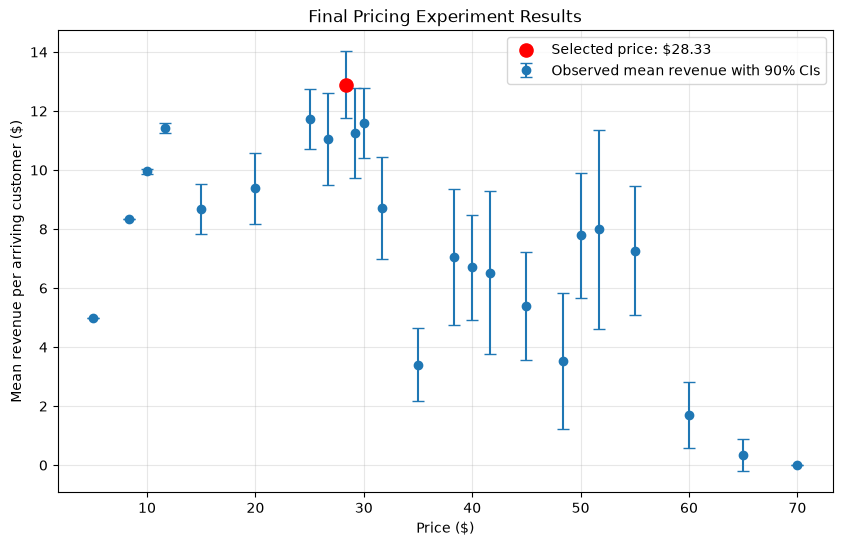

In [18]:
plot_data = final_summary.sort_values("price")

plt.figure(figsize=(10, 6))

plt.errorbar(
    plot_data["price"],
    plot_data["mean_revenue"],
    yerr=1.645 * plot_data["standard_error"],
    fmt="o",
    capsize=4,
    label="Observed mean revenue with 90% CIs"
)

plt.scatter(
    selected_price,
    selected_mean,
    color="red",
    s=90,
    zorder=3,
    label=f"Selected price: ${selected_price:.2f}"
)

plt.xlabel("Price ($)")
plt.ylabel("Mean revenue per arriving customer ($)")
plt.title("Final Pricing Experiment Results")
plt.legend()
plt.grid(alpha=0.3)

plt.show()